<a href="https://colab.research.google.com/github/tejorishi/neur3002/blob/main/ICA_4EncodingViaChatYarlagadda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np

def simulate_rate_coding(stimulus_magnitude_1, stimulus_magnitude_2, total_time=1.0, dt=0.001):
    # Simulation Parameters
    time = np.arange(0, total_time, dt)

    # Mechanoreceptor Transfer Function (Linear approximation of rate coding)
    spontaneous_rate = 10.0 # Spontaneous background firing rate (Hz) - this will be the sustained rate
    gain = 30.0            # Receptor sensitivity

    # Calculate Initial Firing Rates (before adaptation) for each stimulus
    initial_rate_1 = spontaneous_rate + (gain * stimulus_magnitude_1)
    initial_rate_2 = spontaneous_rate + (gain * stimulus_magnitude_2)

    # Adaptation Parameters
    tau_fast = 0.05        # Fast adaptation time constant (seconds)
    tau_slow = 0.3         # Slow adaptation time constant (seconds)

    # Calculate Time-Varying Firing Rates for Adapting Neurons
    # Rate(t) = Spontaneous_rate + (Initial_rate - Spontaneous_rate) * exp(-t / tau)

    # --- Stimulus 1 Responses (e.g., 'Weak Stimulus' from real data) ---
    # Tonic (Non-adapting) Neuron 1
    rate_tonic_1_t = np.full_like(time, initial_rate_1)

    # Fast Adapting Neuron 1
    rate_fast_1_t = spontaneous_rate + (initial_rate_1 - spontaneous_rate) * np.exp(-time / tau_fast)
    rate_fast_1_t[rate_fast_1_t < spontaneous_rate] = spontaneous_rate # Ensure rate doesn't drop below spontaneous

    # Slow Adapting Neuron 1
    rate_slow_1_t = spontaneous_rate + (initial_rate_1 - spontaneous_rate) * np.exp(-time / tau_slow)
    rate_slow_1_t[rate_slow_1_t < spontaneous_rate] = spontaneous_rate

    # --- Stimulus 2 Responses (e.g., 'Strong Stimulus' from real data) ---
    # Tonic (Non-adapting) Neuron 2
    rate_tonic_2_t = np.full_like(time, initial_rate_2)

    # Fast Adapting Neuron 2
    rate_fast_2_t = spontaneous_rate + (initial_rate_2 - spontaneous_rate) * np.exp(-time / tau_fast)
    rate_fast_2_t[rate_fast_2_t < spontaneous_rate] = spontaneous_rate

    # Slow Adapting Neuron 2
    rate_slow_2_t = spontaneous_rate + (initial_rate_2 - spontaneous_rate) * np.exp(-time / tau_slow)
    rate_slow_2_t[rate_slow_2_t < spontaneous_rate] = spontaneous_rate

    # Generate Spike Trains using an Inhomogeneous Poisson Process
    np.random.seed(42) # For reproducibility (ensure consistent spikes for same inputs)

    spikes_tonic_1 = np.random.rand(len(time)) < (rate_tonic_1_t * dt)
    spikes_fast_1 = np.random.rand(len(time)) < (rate_fast_1_t * dt)
    spikes_slow_1 = np.random.rand(len(time)) < (rate_slow_1_t * dt)

    spikes_tonic_2 = np.random.rand(len(time)) < (rate_tonic_2_t * dt)
    spikes_fast_2 = np.random.rand(len(time)) < (rate_fast_2_t * dt)
    spikes_slow_2 = np.random.rand(len(time)) < (rate_slow_2_t * dt)

    # Output Results (counts are still useful)
    count_tonic_1 = np.sum(spikes_tonic_1)
    count_fast_1 = np.sum(spikes_fast_1)
    count_slow_1 = np.sum(spikes_slow_1)
    count_tonic_2 = np.sum(spikes_tonic_2)
    count_fast_2 = np.sum(spikes_fast_2)
    count_slow_2 = np.sum(spikes_slow_2)

    print("--- Somatosensory Rate Coding Simulation ---")
    print(f"Stimulus 1 ({stimulus_magnitude_1} units):")
    print(f"  Tonic (Non-adapting) | Spikes Counted: {count_tonic_1}")
    print(f"  Fast Adapting        | Spikes Counted: {count_fast_1}")
    print(f"  Slow Adapting        | Spikes Counted: {count_slow_1}")
    print(f"Stimulus 2 ({stimulus_magnitude_2} units):")
    print(f"  Tonic (Non-adapting) | Spikes Counted: {count_tonic_2}")
    print(f"  Fast Adapting        | Spikes Counted: {count_fast_2}")
    print(f"  Slow Adapting        | Spikes Counted: {count_slow_2}")

    return (time, spikes_tonic_1, spikes_fast_1, spikes_slow_1,
            spikes_tonic_2, spikes_fast_2, spikes_slow_2, total_time)

if __name__ == "__main__":
    # Example usage with sample 'real data' values
    real_data_stim_1 = 3.5 # Example real data magnitude for first stimulus
    real_data_stim_2 = 6.0 # Example real data magnitude for second stimulus

    (time_data, spikes_tonic_1, spikes_fast_1, spikes_slow_1,
     spikes_tonic_2, spikes_fast_2, spikes_slow_2, total_time) = \
        simulate_rate_coding(real_data_stim_1, real_data_stim_2)

--- Somatosensory Rate Coding Simulation ---
Stimulus 1 (3.5 units):
  Tonic (Non-adapting) | Spikes Counted: 125
  Fast Adapting        | Spikes Counted: 14
  Slow Adapting        | Spikes Counted: 47
Stimulus 2 (6.0 units):
  Tonic (Non-adapting) | Spikes Counted: 191
  Fast Adapting        | Spikes Counted: 21
  Slow Adapting        | Spikes Counted: 63


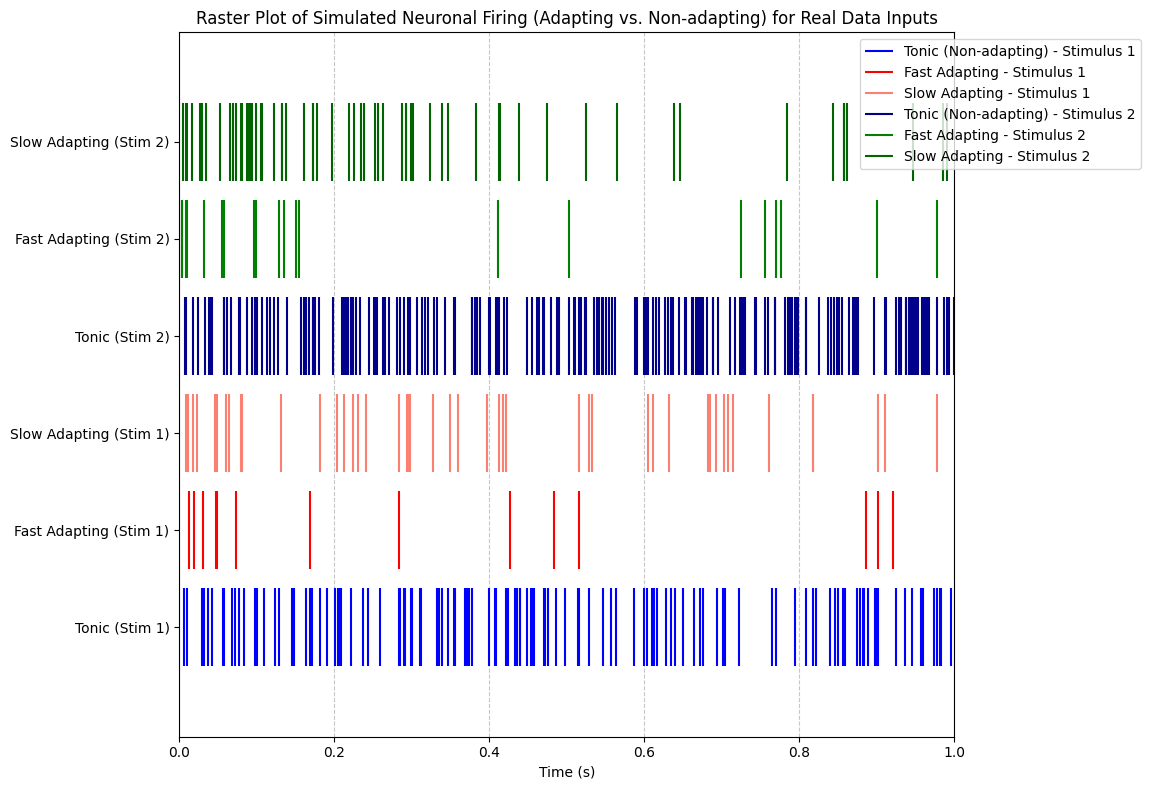

In [13]:
import matplotlib.pyplot as plt

# Create the raster plot
fig, ax = plt.subplots(figsize=(12, 8)) # Make the figure taller to accommodate more neurons

# Plot spikes for each neuron type for Stimulus 1
ax.eventplot(time_data[spikes_tonic_1], lineoffsets=1, linelengths=0.8, color='blue', label='Tonic (Non-adapting) - Stimulus 1')
ax.eventplot(time_data[spikes_fast_1], lineoffsets=2, linelengths=0.8, color='red', label='Fast Adapting - Stimulus 1')
ax.eventplot(time_data[spikes_slow_1], lineoffsets=3, linelengths=0.8, color='salmon', label='Slow Adapting - Stimulus 1')

# Plot spikes for each neuron type for Stimulus 2
ax.eventplot(time_data[spikes_tonic_2], lineoffsets=4, linelengths=0.8, color='darkblue', label='Tonic (Non-adapting) - Stimulus 2')
ax.eventplot(time_data[spikes_fast_2], lineoffsets=5, linelengths=0.8, color='green', label='Fast Adapting - Stimulus 2')
ax.eventplot(time_data[spikes_slow_2], lineoffsets=6, linelengths=0.8, color='darkgreen', label='Slow Adapting - Stimulus 2')

# Set y-axis labels and ticks
ax.set_yticks([1, 2, 3, 4, 5, 6])
ax.set_yticklabels([
    'Tonic (Stim 1)',
    'Fast Adapting (Stim 1)',
    'Slow Adapting (Stim 1)',
    'Tonic (Stim 2)',
    'Fast Adapting (Stim 2)',
    'Slow Adapting (Stim 2)'
])

ax.set_xlabel('Time (s)')
ax.set_title('Raster Plot of Simulated Neuronal Firing (Adapting vs. Non-adapting) for Real Data Inputs')
ax.set_xlim(0, total_time)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1)) # Adjust legend position if it overlaps
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()